# LE03 – pandas: Daten laden, erkunden und auswählen
---
**Selbststudium** · Zeitbedarf ca. 5 Stunden · Phase A/B: Data Understanding und Data Preparation

In LE02 haben Sie Kims Lernprotokoll mit `csv`, Dictionaries und Schleifen ausgewertet. Das hat funktioniert, war aber mühsam: Typen von Hand umwandeln, Summen-Dictionaries anlegen, Tabellen mit f-Strings formatieren. Ab jetzt arbeiten wir mit [**pandas**](https://pandas.pydata.org/), dem zentralen Werkzeug für tabellarische Daten in Python. Der Name leitet sich von *panel data* ab, einem Begriff aus der Statistik für mehrdimensionale Daten.

pandas begleitet Sie durch den Rest des Semesters: beim Laden, Erkunden, Bereinigen, Verknüpfen, Umformen, Aggregieren und Visualisieren.

## Lernziele

Nach dieser Lehreinheit können Sie …

1. die Datenstrukturen `Series` und `DataFrame` erklären und aus Python-Datenstrukturen erzeugen,
2. CSV-, JSON- und Excel-Dateien mit passenden Parametern einlesen,
3. sich mit `head`, `info`, `describe`, `value_counts` und `isna` systematisch einen Überblick über einen Datensatz verschaffen und **Befunde** zur Datenqualität festhalten,
4. die Datentypen von pandas 3 (u. a. `str`, `datetime64`, nullbare Ganzzahlen) erkennen und umwandeln,
5. Spalten und Zeilen mit `[]`, `loc`, `iloc` und Bedingungen auswählen,
6. Daten sortieren und neue Spalten vektorisiert berechnen, einschließlich Text- und Datumsoperationen,
7. erklären, was *Copy-on-Write* in pandas 3 bedeutet und warum verkettete Zuweisungen nicht funktionieren,
8. einfache Gruppierungen und Diagramme erstellen und Ergebnisse als CSV oder Parquet speichern.

## Inhalt

1. Von der Liste von Dictionaries zum DataFrame
2. Daten einlesen
3. Ein erster Überblick
4. Datentypen
5. Auswählen: Spalten, Zeilen, Bedingungen
6. Sortieren
7. Neue Spalten berechnen
8. Copy-on-Write: Werte richtig ändern
9. Ein Vorgeschmack: Gruppieren und Plotten
10. Speichern
11. Selbsttest
12. Zusammenfassung und Vorbereitung auf die Präsenz

## 1 Von der Liste von Dictionaries zum DataFrame
---

pandas wird per Konvention mit dem Kürzel `pd` importiert:

In [1]:
import pandas as pd

pd.__version__

'3.0.6'

pandas kennt zwei zentrale Datenstrukturen:

* Eine **Series** ist eine eindimensionale Folge von Werten mit einem **Index** (Beschriftung). Sie entspricht einer Spalte.
* Ein **DataFrame** ist eine zweidimensionale Tabelle aus mehreren Series, die sich einen Index teilen. Jede Spalte hat einen Namen und einen Datentyp.

Erinnern Sie sich an die beiden Tabellendarstellungen aus LE02? Beide lassen sich direkt in einen DataFrame umwandeln:

In [2]:
zeilen = [
    {"fach": "Mathe", "dauer_min": 95, "fokus": 4},
    {"fach": "Statistik", "dauer_min": 40, "fokus": 3},
    {"fach": "Mathe", "dauer_min": 35, "fokus": 5},
]
df = pd.DataFrame(zeilen)          # aus einer Liste von Dictionaries (zeilenweise)
df

,fach,dauer_min,fokus
0,Mathe,95,4
1,Statistik,40,3
2,Mathe,35,5


In [3]:
spalten = {"fach": ["Mathe", "Statistik", "Mathe"], "dauer_min": [95, 40, 35], "fokus": [4, 3, 5]}
pd.DataFrame(spalten)              # aus einem Dictionary von Listen (spaltenweise)

,fach,dauer_min,fokus
0,Mathe,95,4
1,Statistik,40,3
2,Mathe,35,5


Links sehen Sie den **Index**, standardmäßig die Zeilennummern `0, 1, 2, …`. Eine einzelne Spalte ist eine Series:

In [4]:
dauer = df["dauer_min"]
print(type(dauer))
dauer

<class 'pandas.Series'>


0    95
1    40
2    35
Name: dauer_min, dtype: int64

Der entscheidende Unterschied zu Listen: Rechenoperationen wirken auf **alle Werte gleichzeitig**. Sie brauchen keine Schleife mehr. Dieses Prinzip heißt **Vektorisierung** und ist Thema von LE04.

In [5]:
print(dauer / 60)          # jede Dauer in Stunden
print(dauer.sum(), dauer.mean(), dauer.max())

0    1.583333
1    0.666667
2    0.583333
Name: dauer_min, dtype: float64
170 56.666666666666664 95


Die wichtigsten Attribute eines DataFrames:

In [6]:
print(df.shape)        # (Zeilen, Spalten)
print(df.columns)      # Spaltennamen
print(df.index)        # Zeilenbeschriftungen
print(df.dtypes)       # Datentyp je Spalte

(3, 3)
Index(['fach', 'dauer_min', 'fokus'], dtype='str')
RangeIndex(start=0, stop=3, step=1)
fach           str
dauer_min    int64
fokus        int64
dtype: object


## 2 Daten einlesen
---

In der Praxis erzeugen Sie DataFrames nicht von Hand, sondern lesen Dateien ein. pandas bietet für nahezu jedes Format eine Funktion `pd.read_…` ([Übersicht](https://pandas.pydata.org/docs/user_guide/io.html)).

### CSV

Kims Lernprotokoll mit Stand 01.11.2026 lesen Sie mit einer einzigen Zeile ein. Statt einer Liste von Dictionaries mit lauter Strings erhalten Sie direkt einen DataFrame, und pandas erkennt Zahlen automatisch:

In [7]:
df = pd.read_csv("data/lernsessions_2026-11-01.csv")
df.head()

,datum,start,ende,fach,ort,fokus_1bis5,pausen_anzahl,notiz
0,2026-10-05,10:40,13:10,Statistik,Zuhause,5.0,3,NaN
1,2026-10-05,16:50,18:15,Programmieren,Bibliothek,5.0,1,NaN
2,2026-10-05,23:15,00:25,Statistik,Zuhause,3.0,2,NaN
3,2026-10-06,10:25,12:10,Statistik,Bibliothek,3.0,3,NaN
4,2026-10-06,13:50,14:35,Datenbanken,Bibliothek,3.0,0,NaN


`read_csv` hat viele Parameter. Diese brauchen Sie am häufigsten:

| Parameter | Wirkung | Beispiel |
|---|---|---|
| `sep` | Trennzeichen | `sep=";"` für deutsche Excel-Exporte |
| `decimal` | Dezimaltrennzeichen | `decimal=","` für `3,5` |
| `encoding` | Zeichenkodierung | `encoding="utf-8"` (Standard), `"latin-1"` für ältere Windows-Dateien |
| `header`, `names` | Kopfzeile bzw. eigene Spaltennamen | `header=None, names=["a", "b"]` |
| `usecols` | nur bestimmte Spalten laden | `usecols=["datum", "fach"]` |
| `dtype` | Datentyp vorgeben | `dtype={"plz": "str"}` (sonst verschwinden führende Nullen) |
| `na_values` | weitere Zeichen als fehlend werten | `na_values=["-", "?"]` |
| `parse_dates` | Spalten als Datum einlesen | `parse_dates=["datum"]` |
| `nrows` | nur die ersten Zeilen lesen | `nrows=100` (zum Testen großer Dateien) |

In [8]:
df = pd.read_csv("data/lernsessions_2026-11-01.csv", parse_dates=["datum"])
df.dtypes

datum            datetime64[us]
start                       str
ende                        str
fach                        str
ort                         str
fokus_1bis5             float64
pausen_anzahl             int64
notiz                       str
dtype: object

### JSON

Einfache, **flache** JSON-Dateien (eine Liste gleichartiger Objekte) liest `pd.read_json` direkt ein. Verschachtelte Exporte wie Kims Schlafdaten laden Sie zuerst mit `json.load` und „plätten“ dann die gewünschte Liste mit `pd.json_normalize`. Verschachtelte Schlüssel werden dabei zu Spalten mit Punkt im Namen:

In [9]:
import json

with open("data/schlaf_2026-11-15.json", encoding="utf-8") as f:
    export = json.load(f)

schlaf = pd.json_normalize(export["sleepSessions"])
schlaf.head()

,start,end,score,stages.deep,stages.light,stages.rem,stages.awake
0,2026-10-04T21:10:44Z,2026-10-05T05:05:06Z,60,66,282,102,24
1,2026-10-05T22:46:22Z,2026-10-06T04:41:19Z,38,51,208,74,22
2,2026-10-06T21:13:49Z,2026-10-07T04:55:40Z,55,81,253,97,31
3,2026-10-07T21:51:13Z,2026-10-08T04:26:05Z,48,77,196,86,36
4,2026-10-08T20:45:10Z,2026-10-09T04:14:11Z,64,66,262,104,17


Vergleichen Sie das mit LE02: Dort mussten Sie für jede Nacht Schritt für Schritt auf `n["stages"]["deep"]` zugreifen.

### Excel

Viele erheben ihre Daten in einer Tabellenkalkulation. Excel-Dateien lesen Sie mit `pd.read_excel` (benötigt das Paket `openpyxl`, im Kursprojekt ist es installiert):

```python
df = pd.read_excel("data/raw/tracking.xlsx", sheet_name="Tabelle1")
```

⚠️ In Excel-Dateien stecken oft Formatierungen, verbundene Zellen oder Summenzeilen, die nicht zu den Daten gehören (siehe die Regeln für Rohdaten aus LE02). Prüfen Sie das Ergebnis deshalb immer mit `head()` und `tail()`.

## 3 Ein erster Überblick
---

Bevor Sie Fragen an Daten stellen, verschaffen Sie sich einen **systematischen Überblick**. Das ist der Kern der CRISP-DM-Phase *Data Understanding*. Die folgenden Werkzeuge verwenden Sie bei jedem neuen Datensatz.

**Stichproben ansehen:** `head(n)`, `tail(n)` und `sample(n)` zeigen die ersten, letzten bzw. zufällige Zeilen. Gerade `tail` und `sample` decken Probleme auf, die in den ersten Zeilen nicht vorkommen.

In [10]:
df.sample(5, random_state=1)     # random_state macht die Zufallsauswahl reproduzierbar

,datum,start,ende,fach,ort,fokus_1bis5,pausen_anzahl,notiz
65,2026-10-29,23:15,01:40,Programmieren,Zuhause,3.0,3,NaN
26,2026-10-15,22:50,00:40,Statistik,Zuhause,3.0,2,NaN
66,2026-10-30,10:20,11:35,Datenbanken,Bibliothek,4.0,1,NaN
54,2026-10-26,21:05,21:45,Mathe,Zuhause,4.0,0,NaN
27,2026-10-16,10:15,11:45,Programmieren,Hochschule,5.0,2,NaN


**Struktur:** `info()` fasst Zeilenzahl, Spalten, Datentypen, die Anzahl **nicht fehlender** Werte und den Speicherbedarf zusammen.

In [11]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 70 entries, 0 to 69
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   datum          70 non-null     datetime64[us]
 1   start          70 non-null     str           
 2   ende           70 non-null     str           
 3   fach           70 non-null     str           
 4   ort            67 non-null     str           
 5   fokus_1bis5    66 non-null     float64       
 6   pausen_anzahl  70 non-null     int64         
 7   notiz          9 non-null      str           
dtypes: datetime64[us](1), float64(1), int64(1), str(5)
memory usage: 6.6 KB


Schon hier sehen Sie: `ort` und `fokus_1bis5` haben weniger Einträge als der DataFrame Zeilen hat, es fehlen also Werte. Und `fokus_1bis5` ist vom Typ `float64`, obwohl die Skala ganzzahlig ist. Warum, klärt Abschnitt 4.

**Fehlende Werte zählen:** `isna()` liefert für jede Zelle `True` oder `False`. Die Summe je Spalte zählt die fehlenden Werte:

In [12]:
df.isna().sum()

datum             0
start             0
ende              0
fach              0
ort               3
fokus_1bis5       4
pausen_anzahl     0
notiz            61
dtype: int64

**Kennzahlen:** `describe()` berechnet für numerische Spalten Anzahl, Mittelwert, Standardabweichung, Minimum, Quartile und Maximum. Prüfen Sie hier vor allem, ob **Minimum und Maximum plausibel** sind.

In [13]:
df.describe()

,datum,fokus_1bis5,pausen_anzahl
count,70,66.000000,70.000000
mean,2026-10-18 16:06:51.428571,3.833333,1.600000
min,2026-10-05 00:00:00,1.000000,0.000000
25%,2026-10-13 00:00:00,3.000000,1.000000
50%,2026-10-19 00:00:00,4.000000,2.000000
75%,2026-10-25 18:00:00,4.000000,2.000000
max,2026-11-01 00:00:00,5.000000,4.000000
std,NaN,0.887231,1.082134


Für Textspalten liefert `describe` die Anzahl, die Anzahl verschiedener Werte (`unique`), den häufigsten Wert (`top`) und dessen Häufigkeit (`freq`):

In [14]:
df.describe(include="str")

,start,ende,fach,ort,notiz
count,70,70,70,67,9
unique,47,56,8,5,6
top,16:50,18:15,Programmieren,Zuhause,Lerngruppe
freq,3,2,23,30,3


**Kategorien prüfen:** `value_counts()` zählt, wie oft jeder Wert vorkommt. Mit `dropna=False` werden auch fehlende Werte gezählt. Das ist das wichtigste Werkzeug, um **Schreibvarianten** zu entdecken:

In [15]:
df["fach"].value_counts(dropna=False)

fach
Programmieren     23
Statistik         16
Mathe             14
Datenbanken       12
programmieren      2
Programmieren      1
Mathe              1
mathe              1
Name: count, dtype: int64

Laut Data Dictionary gibt es vier Fächer, `value_counts` zeigt aber mehr Varianten. Mit `normalize=True` erhalten Sie Anteile statt Anzahlen, `nunique()` zählt die verschiedenen Werte und `unique()` listet sie auf.

**Duplikate:** `duplicated()` markiert Zeilen, die einer früheren Zeile vollständig gleichen:

In [16]:
df.duplicated().sum()

np.int64(0)

### Checkliste für den ersten Überblick

Gehen Sie bei jedem neuen Datensatz diese Schritte durch und halten Sie jeden Befund fest. Die Befundliste ist die Grundlage für die Bereinigung in LE05.

| # | Frage | Werkzeug |
|---|---|---|
| 1 | Wurde die Datei richtig gelesen (Trennzeichen, Kopfzeile, Umlaute)? | `head()`, `tail()`, `sample()` |
| 2 | Stimmt die Anzahl der Zeilen und Spalten mit der Erwartung überein? | `shape` |
| 3 | Passen die Datentypen zum Data Dictionary? | `info()`, `dtypes` |
| 4 | Wo fehlen Werte, und wie viele? | `isna().sum()` |
| 5 | Welche Kategorien kommen vor, gibt es Schreibvarianten? | `value_counts(dropna=False)` |
| 6 | Sind Minimum und Maximum plausibel? | `describe()` |
| 7 | Lassen sich alle Werte in das erwartete Format umwandeln (z. B. Datum)? | `pd.to_datetime(…, errors="coerce")` |
| 8 | Gibt es doppelte Zeilen? | `duplicated().sum()` |

💡 Werkzeuge wie [ydata-profiling](https://docs.profiling.ydata.ai/) oder die VS-Code-Erweiterung [Data Wrangler](https://marketplace.visualstudio.com/items?itemName=ms-toolsai.datawrangler) erstellen solche Übersichten automatisch. Sie sind praktisch, ersetzen aber nicht das eigene Nachdenken darüber, was ein Befund *bedeutet*.

## 4 Datentypen
---

Jede Spalte eines DataFrames hat genau einen Datentyp. Die wichtigsten:

| Datentyp | Inhalt | Beispiel |
|---|---|---|
| `int64` | Ganzzahlen **ohne** fehlende Werte | `pausen_anzahl` |
| `float64` | Kommazahlen, auch Ganzzahlen **mit** fehlenden Werten (`NaN`) | `fokus_1bis5` |
| `Int64` | nullbare Ganzzahl: Ganzzahlen mit fehlenden Werten (`<NA>`) | `fokus_1bis5` nach Umwandlung |
| `bool` | Wahrheitswerte | Ergebnis eines Vergleichs |
| `str` | Text (seit pandas 3.0 der Standard für Textspalten) | `fach`, `ort` |
| `datetime64` | Zeitpunkte | `datum` nach `parse_dates` |
| `timedelta64` | Zeitspannen | Differenz zweier Zeitpunkte |
| `category` | Kategorien mit fester Werteliste | Fächer, Wochentage (ab LE09) |
| `object` | beliebige Python-Objekte, z. B. gemischte Typen | Warnsignal beim Einlesen |

**Warum ist `fokus_1bis5` ein `float64`?** Der klassische Ganzzahltyp `int64` kann keine fehlenden Werte darstellen. Sobald eine Zahl fehlt, weicht pandas auf `float64` aus und markiert die Lücke als `NaN` (*Not a Number*). Wenn Sie Ganzzahlen mit Lücken brauchen, verwenden Sie den **nullbaren** Typ `Int64` (großes `I`):

In [17]:
df["fokus_1bis5"].astype("Int64").head(10)

0    5
1    5
2    3
3    3
4    3
5    3
6    3
7    2
8    4
9    4
Name: fokus_1bis5, dtype: Int64

**Umwandeln:** `astype` wandelt in einen Zieltyp um und bricht bei ungültigen Werten ab. `pd.to_numeric` und `pd.to_datetime` können mit `errors="coerce"` ungültige Werte stattdessen in fehlende Werte umwandeln. So **finden** Sie Problemwerte:

In [18]:
werte = pd.Series(["4", "5", "hoch", "3,5", None])
zahlen = pd.to_numeric(werte, errors="coerce")
print(zahlen)
print("Nicht umwandelbar:", werte[zahlen.isna() & werte.notna()].tolist())

0    4.0
1    5.0
2    NaN
3    NaN
4    NaN
dtype: float64
Nicht umwandelbar: ['hoch', '3,5']


⚠️ `errors="coerce"` ist ein Diagnosewerkzeug, keine Bereinigung. Wer es blind einsetzt, verliert unbemerkt Daten, denn aus `"3,5"` wird `NaN` statt `3.5`.

💡 **Text in pandas 3.0:** Ältere pandas-Versionen speicherten Text als `object`. Seit pandas 3.0 erhalten Textspalten automatisch den Datentyp `str`. Viele Beispiele im Netz und manche KI-Antworten zeigen noch `object`, das ist dann veraltet. Taucht in Ihren Daten eine Spalte vom Typ `object` auf, enthält sie meist gemischte Typen, und das ist ein Befund.

## 5 Auswählen: Spalten, Zeilen, Bedingungen
---

### Spalten

In [19]:
df["fach"].head(3)                     # eine Spalte -> Series

0         Statistik
1    Programmieren 
2         Statistik
Name: fach, dtype: str

In [20]:
df[["datum", "fach", "fokus_1bis5"]].head(3)       # mehrere Spalten (Liste!) -> DataFrame

,datum,fach,fokus_1bis5
0,2026-10-05,Statistik,5.0
1,2026-10-05,Programmieren,5.0
2,2026-10-05,Statistik,3.0


💡 Spalten lassen sich auch mit Punktnotation ansprechen (`df.fach`). Das funktioniert aber nicht bei Namen mit Leerzeichen oder bei Namen, die einer Methode gleichen (z. B. eine Spalte `count`). Verwenden Sie deshalb immer `df["fach"]`.

### Zeilen und Zellen: `loc` und `iloc`

pandas unterscheidet zwei Arten des Zugriffs:

* `df.loc[zeilen, spalten]` wählt über **Beschriftungen** (*labels*): Indexwerte und Spaltennamen. Slices schließen das Ende **ein**.
* `df.iloc[zeilen, spalten]` wählt über **Positionen** (*integer location*), wie bei Listen. Slices schließen das Ende **aus**.

In [21]:
df.loc[0:2, ["fach", "fokus_1bis5"]]     # Index 0 bis einschließlich 2

,fach,fokus_1bis5
0,Statistik,5.0
1,Programmieren,5.0
2,Statistik,3.0


In [22]:
df.iloc[0:2, [3, 5]]                     # Positionen 0 und 1, Spalten an Position 3 und 5

,fach,fokus_1bis5
0,Statistik,5.0
1,Programmieren,5.0


Solange der Index aus den Zahlen `0, 1, 2, …` besteht, wirken `loc` und `iloc` ähnlich. Der Unterschied wird deutlich, sobald der Index etwas anderes enthält, z. B. nach dem Sortieren oder mit `set_index`:

In [23]:
nach_pausen = df.sort_values("pausen_anzahl", ascending=False)
print(nach_pausen.loc[0, "fach"])     # Zeile mit dem Index 0, egal wo sie steht
print(nach_pausen.iloc[0]["fach"])    # erste Zeile in der aktuellen Reihenfolge

Statistik
Programmieren


### Bedingungen (Boolean Indexing)

Ein Vergleich mit einer Spalte liefert eine Series aus `True` und `False`, eine sogenannte **Maske**. In eckigen Klammern oder in `loc` wählt die Maske alle Zeilen mit `True` aus:

In [24]:
maske = df["ort"] == "Bibliothek"
df[maske].head(3)

,datum,start,ende,fach,ort,fokus_1bis5,pausen_anzahl,notiz
1,2026-10-05,16:50,18:15,Programmieren,Bibliothek,5.0,1,NaN
3,2026-10-06,10:25,12:10,Statistik,Bibliothek,3.0,3,NaN
4,2026-10-06,13:50,14:35,Datenbanken,Bibliothek,3.0,0,NaN


Mehrere Bedingungen verknüpfen Sie mit `&` (und), `|` (oder) und `~` (nicht). Jede Bedingung steht dabei in **Klammern**, denn `and` und `or` funktionieren hier nicht:

In [25]:
df.loc[(df["ort"] == "Bibliothek") & (df["fokus_1bis5"] >= 5), ["datum", "start", "fach"]]

,datum,start,fach
1,2026-10-05,16:50,Programmieren
14,2026-10-12,14:10,programmieren
48,2026-10-25,08:05,Programmieren


Weitere nützliche Bedingungen:

| Ausdruck | Bedeutung |
|---|---|
| `df["fach"].isin(["Mathe", "Statistik"])` | Wert ist in einer Liste enthalten |
| `df["pausen_anzahl"].between(1, 3)` | Wert liegt im Bereich (einschließlich der Grenzen) |
| `df["notiz"].str.contains("Klausur", na=False)` | Text enthält einen Teilstring |
| `df["ort"].isna()` / `notna()` | Wert fehlt bzw. fehlt nicht |

`query` erlaubt Bedingungen als lesbaren String. Das ist vor allem bei langen Bedingungen praktisch:

In [44]:
df.query("ort == 'Bibliothek' and fokus_1bis5 >= 5").shape

(3, 11)

✏️ **Ausprobieren:** Wie viele Sessions hat Kim am Sonntag, dem 01.11.2026, eingetragen? Welche Sessions haben eine Notiz? Zeigen Sie für diese nur `datum`, `fach` und `notiz` an.

In [27]:
# Ihr Code

## 6 Sortieren
---

`sort_values` sortiert nach einer oder mehreren Spalten, `sort_index` nach dem Index. `nlargest` und `nsmallest` liefern direkt die *n* größten bzw. kleinsten Zeilen:

In [28]:
df.sort_values(["datum", "start"], ascending=[False, True]).head(3)

,datum,start,ende,fach,ort,fokus_1bis5,pausen_anzahl,notiz
68,2026-11-01,13:55,15:10,Mathe,Zuhause,3.0,2,NaN
69,2026-11-01,21:30,23:15,programmieren,Zuhause,5.0,2,NaN
66,2026-10-30,10:20,11:35,Datenbanken,Bibliothek,4.0,1,NaN


In [29]:
df.nlargest(3, "pausen_anzahl")[["datum", "fach", "pausen_anzahl"]]

,datum,fach,pausen_anzahl
12,2026-10-11,Programmieren,4
37,2026-10-20,Programmieren,4
61,2026-10-28,Programmieren,4


💡 Fast alle pandas-Methoden geben einen **neuen** DataFrame zurück und lassen das Original unverändert. Um das Ergebnis zu behalten, weisen Sie es zu: `df = df.sort_values("datum")`. Den Parameter `inplace=True`, den Sie in älteren Beispielen finden, brauchen Sie nicht.

## 7 Neue Spalten berechnen
---

Eine neue Spalte entsteht durch Zuweisung. Rechnungen wirken wieder auf alle Zeilen gleichzeitig:

In [30]:
df["fokus_prozent"] = df["fokus_1bis5"] / 5
df[["fokus_1bis5", "fokus_prozent"]].head(3)

,fokus_1bis5,fokus_prozent
0,5.0,1.0
1,5.0,1.0
2,3.0,0.6


### Textspalten: der `.str`-Accessor

Über `.str` stehen alle String-Methoden aus LE01 für eine ganze Spalte zur Verfügung:

In [31]:
df["fach"] = df["fach"].str.strip().str.title()
df["fach"].value_counts()

fach
Programmieren    26
Statistik        16
Mathe            16
Datenbanken      12
Name: count, dtype: int64

### Datums- und Zeitspalten: der `.dt`-Accessor

Für `datetime64`-Spalten liefert `.dt` Bestandteile wie Jahr, Monat, Wochentag oder Stunde. Zusammen mit `map` und der Wochentagsliste aus LE02 erhalten Sie deutsche Kürzel:

In [32]:
WOCHENTAGE = ["Mo", "Di", "Mi", "Do", "Fr", "Sa", "So"]

df["wochentag"] = df["datum"].dt.dayofweek.map(dict(enumerate(WOCHENTAGE)))
df[["datum", "wochentag"]].head(3)

,datum,wochentag
0,2026-10-05,Mo
1,2026-10-05,Mo
2,2026-10-05,Mo


Und die Dauer? Setzen Sie Datum und Uhrzeit zu Zeitpunkten zusammen, bilden Sie die Differenz und korrigieren Sie Sessions über Mitternacht. `where` behält einen Wert, wo die Bedingung gilt, und ersetzt ihn sonst:

In [33]:
beginn = pd.to_datetime(df["datum"].dt.strftime("%Y-%m-%d") + " " + df["start"])
ende = pd.to_datetime(df["datum"].dt.strftime("%Y-%m-%d") + " " + df["ende"])
ende = ende.where(ende >= beginn, ende + pd.Timedelta(days=1))    # über Mitternacht

df["dauer_min"] = ((ende - beginn).dt.total_seconds() / 60).astype(int)
df[["datum", "start", "ende", "dauer_min"]].head(5)

,datum,start,ende,dauer_min
0,2026-10-05,10:40,13:10,150
1,2026-10-05,16:50,18:15,85
2,2026-10-05,23:15,00:25,70
3,2026-10-06,10:25,12:10,105
4,2026-10-06,13:50,14:35,45


Vergleichen Sie das mit LE02: Dort brauchten Sie eine eigene Funktion und eine Schleife über alle Zeilen. Hier genügen vier Zeilen für den gesamten Datensatz.

**Weitere nützliche Werkzeuge:**

* `df.rename(columns={"fokus_1bis5": "fokus"})` benennt Spalten um.
* `df.drop(columns=["notiz"])` entfernt Spalten.
* `df.assign(dauer_h=df["dauer_min"] / 60)` erzeugt neue Spalten und gibt einen neuen DataFrame zurück. Das eignet sich gut für Verkettungen mehrerer Schritte.
* `s.map(funktion_oder_dict)` wendet eine Funktion oder Zuordnung auf jeden Wert einer Series an.

✏️ **Ausprobieren:** Fügen Sie eine Spalte `stunde` mit der Startstunde als Ganzzahl hinzu (Tipp: `.str[:2]` und `astype`). Wie viele Sessions beginnen vor 10 Uhr?

In [34]:
# Ihr Code

## 8 Copy-on-Write: Werte richtig ändern
---

Seit pandas 3.0 gilt **Copy-on-Write**: Jede Auswahl aus einem DataFrame verhält sich wie eine eigenständige Kopie. Änderungen an der Auswahl wirken sich nie auf das Original aus. Das macht das Verhalten vorhersehbar, hat aber eine wichtige Konsequenz: **Verkettete Zuweisungen funktionieren nicht.**

In [35]:
kopie = df.copy()
kopie["fokus_1bis5"][kopie["ort"] == "Zug"] = 0      # verkettet: zuerst Spalte, dann Zeilen
kopie.loc[kopie["ort"] == "Zug", "fokus_1bis5"].head()

/tmp/ipykernel_22014/978962481.py:2: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment.
Such chained assignment never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

Try using '.loc[row_indexer, col_indexer] = value' instead, to perform the assignment in a single step.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html#chained-assignment
  kopie["fokus_1bis5"][kopie["ort"] == "Zug"] = 0      # verkettet: zuerst Spalte, dann Zeilen


12    3.0
50    4.0
Name: fokus_1bis5, dtype: float64

pandas warnt mit einem `ChainedAssignmentError`, und die Werte bleiben unverändert. Richtig ist **ein einziger** `loc`-Zugriff mit Zeilen **und** Spalte:

In [36]:
kopie.loc[kopie["ort"] == "Zug", "fokus_1bis5"] = 0
kopie.loc[kopie["ort"] == "Zug", "fokus_1bis5"].head()

12    0.0
50    0.0
Name: fokus_1bis5, dtype: float64

Merken Sie sich:

* **Werte ändern immer mit `df.loc[bedingung, "spalte"] = wert`.**
* Eine Teilmenge wie `mathe = df[df["fach"] == "Mathe"]` können Sie gefahrlos weiterverarbeiten. Das Original bleibt unberührt.
* Die berüchtigte `SettingWithCopyWarning` und die vielen `.copy()`-Aufrufe aus älteren Beispielen sind in pandas 3 nicht mehr nötig.

## 9 Ein Vorgeschmack: Gruppieren und Plotten
---

Die Gruppierung, für die Sie in LE02 Summen-Dictionaries angelegt haben, erledigt pandas mit `groupby`. Aus *„gruppiere nach Fach, nimm die Spalte Dauer, bilde die Summe“* wird:

In [37]:
df.groupby("fach")["dauer_min"].sum().sort_values(ascending=False)

fach
Programmieren    2880
Statistik        1550
Mathe            1140
Datenbanken       875
Name: dauer_min, dtype: int64

Und die Tabelle Wochentag × Fach aus der LE02-Präsenz entsteht mit `pivot_table`:

In [38]:
df.pivot_table(index="wochentag", columns="fach", values="dauer_min", aggfunc="sum", fill_value=0)

fach,Datenbanken,Mathe,Programmieren,Statistik
wochentag,,,,
Di,205,165,370,200
Do,165,280,215,440
Fr,205,85,90,0
Mi,135,160,935,170
Mo,95,100,590,365
Sa,0,0,0,250
So,70,350,680,125


Die Wochentage erscheinen hier noch alphabetisch sortiert. Wie man eine eigene Reihenfolge festlegt und was hinter Gruppierungen und Pivottabellen steckt, lernen Sie ausführlich in LE09.

Mit `.plot` erstellen Sie aus einer Series oder einem DataFrame direkt ein Diagramm (pandas verwendet dafür Matplotlib, Thema von LE10):

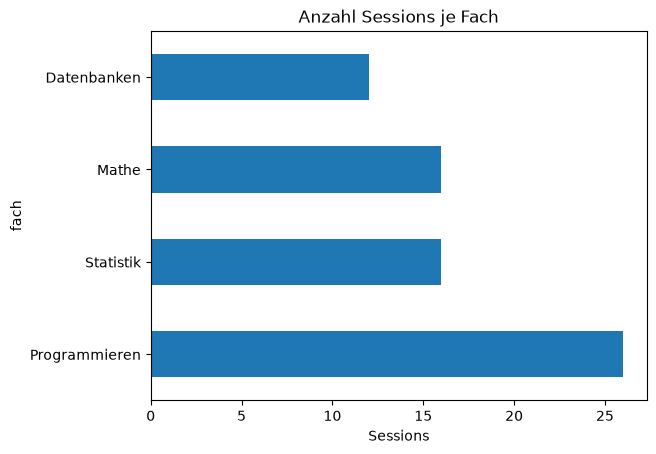

In [39]:
ax = df["fach"].value_counts().plot.barh(title="Anzahl Sessions je Fach")
ax.set_xlabel("Sessions");

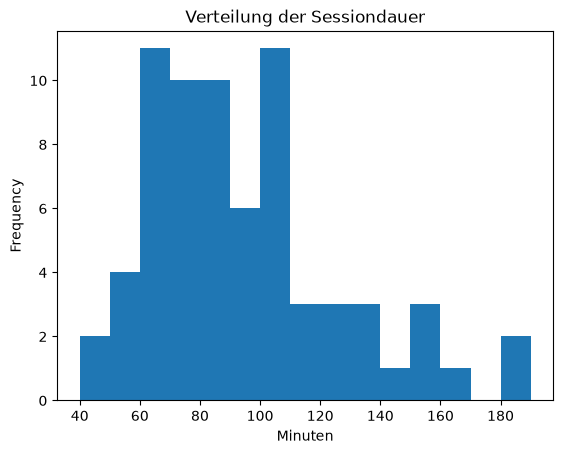

In [40]:
ax = df["dauer_min"].plot.hist(bins=15, title="Verteilung der Sessiondauer")
ax.set_xlabel("Minuten");

## 10 Speichern
---

Mit `to_csv` speichern Sie einen DataFrame als CSV. `index=False` verhindert, dass der Index als zusätzliche Spalte geschrieben wird:

```python
df.to_csv("data/processed/lernsessions.csv", index=False)
```

CSV verliert allerdings die Datentypen: Datumsangaben werden wieder zu Text, `Int64` zu gewöhnlichen Zahlen. Für aufbereitete Zwischenergebnisse eignet sich das Format **Parquet** besser. Es speichert die Datentypen mit, ist kompakt und wird schnell gelesen (benötigt das Paket `pyarrow`, im Kursprojekt ist es installiert):

```python
df.to_parquet("data/processed/lernsessions.parquet")
df = pd.read_parquet("data/processed/lernsessions.parquet")
```

⚠️ Speichern Sie Ergebnisse nie über die Rohdaten. Aufbereitete Daten gehören nach `data/processed/`.

## 11 Selbsttest
---

In [41]:
from dskurs.selbsttest import selbsttest

selbsttest("LE03")

## 12 Zusammenfassung und Vorbereitung auf die Präsenz
---

**Das Wichtigste in Kürze**

* Ein **DataFrame** ist eine Tabelle aus **Series** mit gemeinsamem Index. Rechnungen wirken auf ganze Spalten (Vektorisierung).
* `read_csv`, `read_excel` und `json_normalize` laden Daten. Parameter wie `sep`, `decimal`, `dtype` und `parse_dates` steuern das Einlesen.
* Ein **erster Überblick** folgt einer Checkliste: `head/tail/sample`, `shape`, `info`, `isna().sum()`, `value_counts(dropna=False)`, `describe`, Formatprüfung, `duplicated`. Jeder Befund wird notiert.
* Ganzzahlen mit Lücken werden zu `float64`, der nullbare Typ `Int64` hält sie ganzzahlig. Text ist in pandas 3 vom Typ `str`. `errors="coerce"` findet Problemwerte.
* `[]` für Spalten, `loc` für Beschriftungen, `iloc` für Positionen, Masken mit `&`, `|`, `~` und Klammern.
* Neue Spalten entstehen per Zuweisung. `.str` und `.dt` bieten Text- und Datumsoperationen für ganze Spalten.
* **Copy-on-Write:** Werte ändern Sie mit `df.loc[bedingung, "spalte"] = wert`, nie verkettet.
* `groupby` und `pivot_table` ersetzen die Summen-Dictionaries aus LE02. Aufbereitete Daten speichern Sie als Parquet oder CSV in `data/processed/`.

**Checkliste bis zur Präsenz**

- [ ] Dieses Notebook läuft komplett durch (*Restart Kernel and Run All*).
- [ ] Den Selbsttest habe ich bearbeitet.
- [ ] Meine Datenerhebung läuft, die bisherigen Rohdaten liegen in `data/raw/` meines Projekts.
- [ ] In meinem Projekt ist pandas installiert (`uv add pandas`, falls noch nicht geschehen).

### Weiterführende Quellen

* McKinney, W. (2022): [*Python for Data Analysis*](https://wesmckinney.com/book/), 3. Auflage, Kapitel 5 (Getting Started with pandas) und 6 (Data Loading).
* [pandas User Guide](https://pandas.pydata.org/docs/user_guide/index.html), insbesondere [10 minutes to pandas](https://pandas.pydata.org/docs/user_guide/10min.html) und [Indexing and selecting data](https://pandas.pydata.org/docs/user_guide/indexing.html)
* [Copy-on-Write in pandas](https://pandas.pydata.org/docs/user_guide/copy_on_write.html)
* [Neuerungen in pandas 3.0](https://pandas.pydata.org/docs/whatsnew/v3.0.0.html)